# 070 CASE 100 — Tutorial: write your own analyzer

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** How do you add a new analysis method to IMINT Engine?

**Area:** Farmland around Eslöv (Skåne), 29 July 2024.

**Partners:** Open to the community

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Contains modified Copernicus Sentinel data 2024.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus Jupyter and the plotting
libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1abd4653cb843a75557b05c09915fb85904" jupyterlab folium matplotlib
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own DES
account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password; see [digitalearth.se](https://digitalearth.se) for access. Every data fetch goes through
that login, nothing is saved in the notebook, and without a login the fetch stops with an error.
There is no synthetic fallback: every figure comes from real Sentinel-2 data. A run takes about a minute.

## Log in to Digital Earth Sweden

In [ ]:
from getpass import getpass

import imint.fetch
import openeo
from IPython.display import clear_output

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    user, password = input("DES username: "), getpass("DES password: ")
    if not (user and password):
        raise ValueError("enter both a DES username and a password")
    des.authenticate_basic(user, password)
    del password
else:
    des.authenticate_oidc(provider_id="egi")

# Every IMINT Engine fetch below uses this login and no other credentials on the machine
# (the pinned engine has no public parameter for a connection yet).
imint.fetch._connect = lambda token=None, token_path=None: des
clear_output()  # keep the typed username and the login link out of a saved notebook
print("Logged in to Digital Earth Sweden.")


## 1. The analyzer contract

Every analyzer subclasses `BaseAnalyzer`, sets a `name`, and implements `analyze(...)`, which returns
an `AnalysisResult(analyzer, success, outputs, metadata)`. The engine calls `run(...)`, which wraps
`analyze` so a failing analyzer never stops the pipeline. Here we write an NDRE analyzer:
NDRE = (B8A − B05) / (B8A + B05), a red-edge index that reacts to crop stress earlier than NDVI.

In [2]:
from __future__ import annotations

import numpy as np
from imint.analyzers.base import AnalysisResult, BaseAnalyzer


class NDREAnalyzer(BaseAnalyzer):
    """Normalised difference red edge: early sign of crop water or nutrient stress."""

    name = "ndre"

    def analyze(self, rgb, bands=None, date=None, coords=None, output_dir="outputs",
                scl=None, geo=None) -> AnalysisResult:
        threshold = self.config.get("stress_threshold", 0.2)
        b05, b8a = bands["B05"].astype(float), bands["B8A"].astype(float)
        ndre = (b8a - b05) / np.maximum(b8a + b05, 1e-10)
        if scl is not None:
            ndre = np.where(np.isin(scl, [4]), ndre, np.nan)  # keep vegetation pixels (SCL 4)
        stress = ndre < threshold
        return AnalysisResult(
            analyzer=self.name, success=True,
            outputs={"ndre": ndre, "stress_mask": stress & ~np.isnan(ndre),
                     "stress_fraction": float(np.nanmean(np.where(np.isnan(ndre), np.nan, stress)))},
            metadata={"stress_threshold": threshold},
        )

## 2. Test it on known values first

In [3]:
healthy = {"B05": np.full((10, 10), 0.10), "B8A": np.full((10, 10), 0.50)}
stressed = {"B05": np.full((10, 10), 0.30), "B8A": np.full((10, 10), 0.35)}
rgb = np.zeros((10, 10, 3))

r1 = NDREAnalyzer({"stress_threshold": 0.2}).run(rgb=rgb, bands=healthy)
r2 = NDREAnalyzer({"stress_threshold": 0.2}).run(rgb=rgb, bands=stressed)
assert r1.success and r2.success
assert abs(np.nanmean(r1.outputs["ndre"]) - 0.4 / 0.6) < 1e-9 and r1.outputs["stress_fraction"] == 0.0
assert r2.outputs["stress_fraction"] == 1.0
print("tests pass:", r1.summary(), "|", r2.summary())

tests pass: [ndre] OK — outputs: ndre, stress_mask, stress_fraction | [ndre] OK — outputs: ndre, stress_mask, stress_fraction


## 3. Run it on real data

In [4]:
import matplotlib.pyplot as plt

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud)
    nodata = np.all(np.stack([a == 0 for a in scene.bands.values()]), axis=0)
    if nodata.mean() > 0.01:  # the archive sometimes holds only part of a scene
        raise ValueError(f"{date}: {nodata.mean():.0%} of the area has no data in this DES scene; use another date")
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud and shadow {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene

AOI = {"west": 13.20, "south": 55.80, "east": 13.40, "north": 55.90}  # around Eslöv, Skåne
DATE = "2024-07-29"

scene = load_scene(DATE, AOI)
THRESHOLD = 0.3  # a parameter to calibrate per crop and date, not a fixed rule
res = NDREAnalyzer({"stress_threshold": THRESHOLD}).run(rgb=scene.rgb, bands=scene.bands, date=DATE,
                                                       coords=AOI, scl=scene.scl, geo=scene.geo)
print(res.summary())
ndre = res.outputs["ndre"]
print("NDRE over vegetation pixels, percentiles 5/25/50/75/95:",
      np.round(np.nanpercentile(ndre, [5, 25, 50, 75, 95]), 2))
print(f"vegetation pixels below NDRE {THRESHOLD}: {res.outputs['stress_fraction']:.1%}")

    Cloud fraction: 0.1%
2024-07-29: 11 bands, 1145 x 1280 px at 10 m, cloud and shadow 0.1% (SCL), CRS EPSG:3006
[ndre] OK — outputs: ndre, stress_mask, stress_fraction
NDRE over vegetation pixels, percentiles 5/25/50/75/95: [0.31 0.4  0.5  0.64 0.72]
vegetation pixels below NDRE 0.3: 3.8%


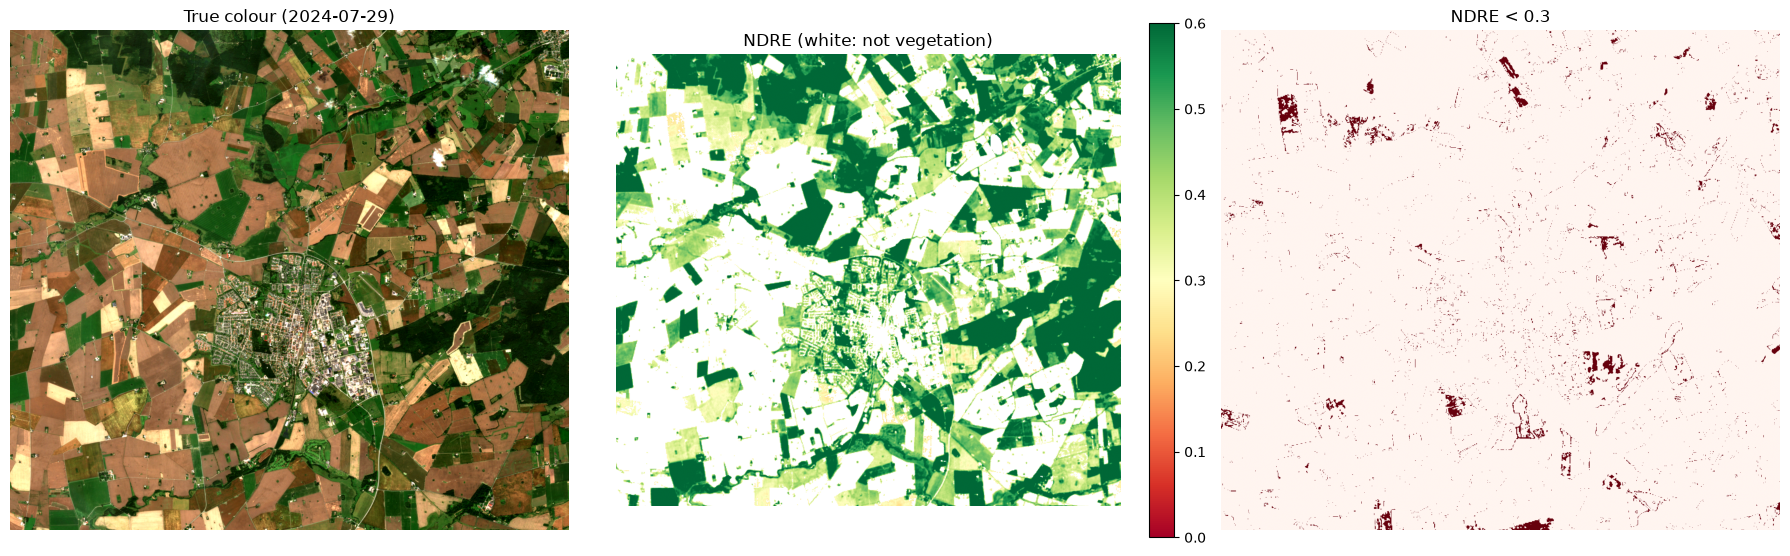

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(scene.rgb); axes[0].set_title(f"True colour ({DATE})")
im = axes[1].imshow(res.outputs["ndre"], cmap="RdYlGn", vmin=0, vmax=0.6); axes[1].set_title("NDRE (white: not vegetation)")
fig.colorbar(im, ax=axes[1], fraction=0.046)
axes[2].imshow(res.outputs["stress_mask"], cmap="Reds"); axes[2].set_title(f"NDRE < {THRESHOLD}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Contribute it

1. Put the class in `imint/analyzers/ndre.py` and the tests in `tests/test_ndre.py`.
2. Register it in `ANALYZER_REGISTRY` in [`imint/engine.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/engine.py) and add a section to
   `config/analyzers.yaml`.
3. If it uses model weights, record their licence in `THIRD_PARTY_LICENSES.md`.
4. Open a pull request against [DigitalEarthSwedenExperimentalLab/imintengine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine).

A July scene mixes crops at different stages, harvested fields and grass, so a low NDRE here is a
prompt to look closer, not a diagnosis.

**Links:** [`imint/analyzers/base.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/base.py)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).